# Breast Cancer Prediction Using Machine Learning

### Machine Learning Project

**Algorithms Used:**
- Logistic Regression
- Random Forest

**Dataset:** Breast Cancer Wisconsin Dataset

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("All libraries imported successfully!")


All libraries imported successfully!


data = load_breast_cancer()

In [12]:
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

print("Dataset loaded successfully!")
print("Features:", X.shape[1])
print("Total samples:", X.shape[0])

Dataset loaded successfully!
Features: 30
Total samples: 569


In [13]:
print("Dataset Shape:", X.shape)

print("\nFirst 5 rows:")
display(X.head())

print("\nTarget values:")
print(y.value_counts())


Dataset Shape: (569, 30)

First 5 rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Target values:
target
1    357
0    212
Name: count, dtype: int64


## 2. Data Splitting

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


## 3. Logistic Regression Model

In [15]:
model = LogisticRegression(max_iter=10000)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [16]:
# Make predictions on test data
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Model Accuracy: 0.9649122807017544
Accuracy Percentage: 96.49122807017544 %


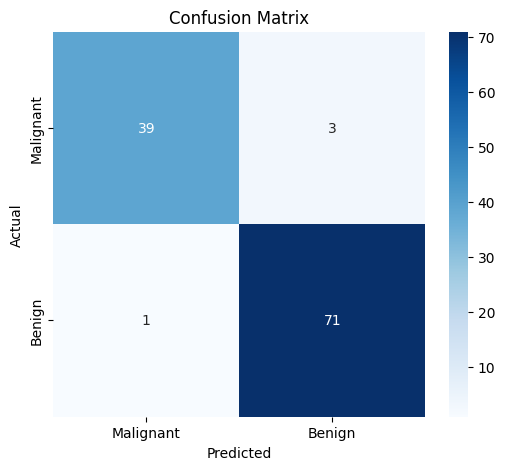

In [17]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Malignant", "Benign"],
    yticklabels=["Malignant", "Benign"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [18]:
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=["Malignant", "Benign"]))

Classification Report:
              precision    recall  f1-score   support

   Malignant       0.97      0.93      0.95        42
      Benign       0.96      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



## 5. Random Forest Model

In [19]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", rf_accuracy)
print("Random Forest Accuracy Percentage:", rf_accuracy * 100, "%")

Random Forest Accuracy: 0.956140350877193
Random Forest Accuracy Percentage: 95.6140350877193 %


In [20]:
# Sample patient from the test dataset
sample = X_test.iloc[[0]]

prediction = model.predict(sample)[0]

if prediction == 0:
    result = "Malignant"
else:
    result = "Benign"

print("Predicted Result:", result)

Predicted Result: Malignant


In [21]:
def predict_breast_cancer(sample_data):
    prediction = model.predict(sample_data)[0]

    if prediction == 0:
        return "Malignant"
    else:
        return "Benign"

print("Prediction system is ready!")

Prediction system is ready!


## 6. Model Comparison

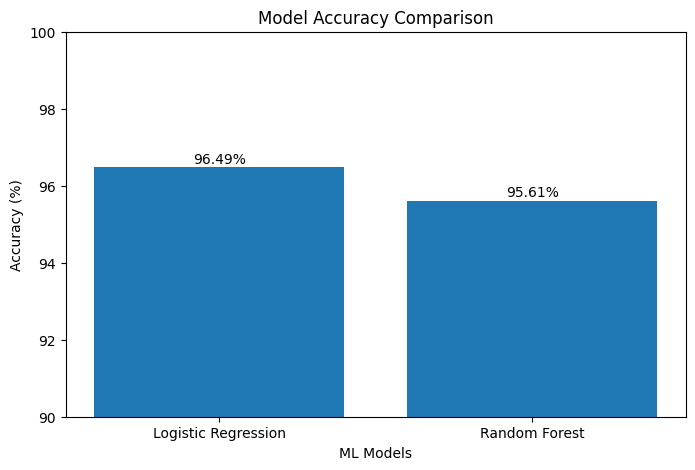

In [22]:
models = ["Logistic Regression", "Random Forest"]
accuracies = [accuracy * 100, rf_accuracy * 100]

plt.figure(figsize=(8, 5))
bars = plt.bar(models, accuracies)

plt.ylabel("Accuracy (%)")
plt.xlabel("ML Models")
plt.title("Model Accuracy Comparison")
plt.ylim(90, 100)

for bar, value in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.1,
        f"{value:.2f}%",
        ha="center"
    )

plt.show()

## 7. Final Prediction

In [23]:
# Final prediction demonstration

sample = X_test.iloc[[0]]

actual = y_test.iloc[0]
predicted = model.predict(sample)[0]

actual_result = "Malignant" if actual == 0 else "Benign"
predicted_result = "Malignant" if predicted == 0 else "Benign"

print("===== Breast Cancer Prediction =====")
print("Actual Result    :", actual_result)
print("Predicted Result :", predicted_result)

if actual == predicted:
    print("Prediction Status: Correct ✓")
else:
    print("Prediction Status: Incorrect")

===== Breast Cancer Prediction =====
Actual Result    : Malignant
Predicted Result : Malignant
Prediction Status: Correct ✓


In [24]:
print("===== FINAL PROJECT RESULTS =====")

print("Logistic Regression Accuracy:", round(accuracy * 100, 2), "%")
print("Random Forest Accuracy:", round(rf_accuracy * 100, 2), "%")

if accuracy > rf_accuracy:
    print("Best Model: Logistic Regression")
else:
    print("Best Model: Random Forest")

===== FINAL PROJECT RESULTS =====
Logistic Regression Accuracy: 96.49 %
Random Forest Accuracy: 95.61 %
Best Model: Logistic Regression


## Conclusion

This project demonstrates the use of Machine Learning for breast cancer classification.

Two Machine Learning algorithms were implemented:
1. Logistic Regression
2. Random Forest

Logistic Regression achieved an accuracy of 96.49%, while Random Forest achieved an accuracy of 95.61%.

Based on the test results, Logistic Regression performed better on this dataset.

The project shows how Machine Learning can be used to classify breast cancer data based on different medical features.

Note: This project is developed for educational purposes only and should not be used as a substitute for professional medical diagnosis.